# Pressure Poisson Equation on the Arakawa C-Grid

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/jejjohnson/sesmax/blob/main/docs/notebooks/pressure_poisson.ipynb)

This notebook demonstrates solving the **pressure Poisson equation** $\nabla^2 p = \nabla \cdot \mathbf{u}$ on the Arakawa C-grid and using the result to project a velocity field to be divergence-free. The grid, operators and spectral solvers are gridax's; the wrapper [`pressure_from_divergence`](xref:api#sesmax_core.pressure_from_divergence) is sesmax's.

**What you will learn:**

1. Where pressure, $u$ and $v$ live on the C-grid
2. How to project a velocity field to be discretely divergence-free
3. How the two Dirichlet spectral solvers (DST-I and DST-II) differ
4. How the one-line sesmax wrapper maps onto the spectral solver

## C-Grid Variable Placement

```
    X ── V ── X ── V ── X
    |         |         |
    U    T    U    T    U     T = tracer / pressure (cell centre)
    |         |         |     U = u-velocity (east face)
    X ── V ── X ── V ── X     V = v-velocity (north face)
    |         |         |     X = vorticity (corner)
    U    T    U    T    U
    |         |         |
    X ── V ── X ── V ── X
```

The C-grid divergence at T-points uses backward differences of face velocities, while the pressure gradient uses forward differences. Their composition $\nabla \cdot \nabla p$ gives exactly the 5-point Laplacian, which the spectral DST-II solver inverts when $p = 0$ sits on the wall faces.

## Setup

On Colab, install `sesmax-core`; locally, with the repository's environment, this does nothing.

In [1]:
import subprocess
import sys


try:
    import google.colab  # noqa: F401

    IN_COLAB = True
except ImportError:
    IN_COLAB = False

if IN_COLAB:
    subprocess.run(
        [
            sys.executable,
            "-m",
            "pip",
            "install",
            "-q",
            "sesmax-core @ git+https://github.com/jejjohnson/sesmax@main"
            "#subdirectory=packages/sesmax-core",
        ],
        check=True,
    )

In [2]:
import warnings


warnings.filterwarnings("ignore", message=r".*IProgress.*")

import equinox as eqx
import gridax
import gridax.solvers
import jax
import jax.numpy as jnp
import matplotlib.pyplot as plt
import numpy as np

import sesmax_core.gfd as gfd


jax.config.update("jax_enable_x64", True)

In [3]:
import importlib.util


try:
    from IPython import get_ipython

    ipython = get_ipython()
except ImportError:
    ipython = None

if ipython is not None and importlib.util.find_spec("watermark") is not None:
    ipython.run_line_magic("load_ext", "watermark")
    ipython.run_line_magic(
        "watermark",
        "-v -m -p numpy,matplotlib,jax,gridax,sesmax_core",
    )
else:
    print("watermark extension not installed; skipping reproducibility readout.")

Python implementation: CPython
Python version       : 3.13.12
IPython version      : 9.10.0

numpy      : 2.4.4
matplotlib : 3.11.2
jax        : 0.12.0.1
gridax     : 0.2.0
sesmax_core: 0.2.0

Compiler    : Clang 21.1.4 
OS          : Linux
Release     : 6.8.0-1044-azure
Machine     : x86_64
Processor   : x86_64
CPU cores   : 16
Architecture: 64bit



## 1. Grid Construction

We build a `CartesianCGrid2D` with a 2-cell ghost ring.  The interior has `nx × ny` T-points; the full array shape is `(ny+2) × (nx+2)`.

In [4]:
nx, ny = 64, 32
Lx, Ly = 4e6, 2e6  # 4000 km × 2000 km basin

grid = gridax.CartesianCGrid2D.from_interior(nx, ny, Lx, Ly)
dx, dy = grid.spacing("x"), grid.spacing("y")
Ny, Nx = ny + 2, nx + 2

print(f"Interior: {nx}×{ny},  dx={dx / 1e3:.0f} km,  dy={dy / 1e3:.0f} km")
print(f"Full array shape: ({Ny}, {Nx})")

Interior: 64×32,  dx=62 km,  dy=62 km
Full array shape: (34, 66)


### Grid point locations

A small 8×4 grid shows how T, U, and V points are staggered.

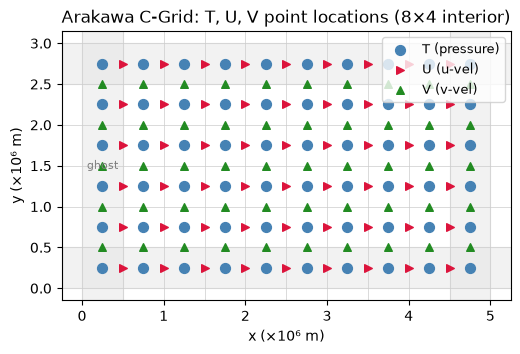

In [5]:
grid_small = gridax.CartesianCGrid2D.from_interior(8, 4, Lx, Ly)
dx_s, dy_s = grid_small.spacing("x"), grid_small.spacing("y")

# T-points at cell centres
t_x = (np.arange(10) + 0.5) * dx_s
t_y = (np.arange(6) + 0.5) * dy_s
Tx, Ty = np.meshgrid(t_x, t_y)

# U-points at east faces
u_x = np.arange(1, 10) * dx_s
u_y = (np.arange(6) + 0.5) * dy_s
Ux, Uy = np.meshgrid(u_x, u_y)

# V-points at north faces
v_x = (np.arange(10) + 0.5) * dx_s
v_y = np.arange(1, 6) * dy_s
Vx, Vy = np.meshgrid(v_x, v_y)

fig, ax = plt.subplots(figsize=(8, 3.5))
ax.scatter(Tx / 1e6, Ty / 1e6, c="steelblue", s=50, zorder=3, label="T (pressure)")
ax.scatter(
    Ux / 1e6, Uy / 1e6, c="crimson", s=30, marker=">", zorder=3, label="U (u-vel)"
)
ax.scatter(
    Vx / 1e6, Vy / 1e6, c="forestgreen", s=30, marker="^", zorder=3, label="V (v-vel)"
)

for i in range(11):
    ax.axvline(i * dx_s / 1e6, color="0.8", lw=0.5)
for j in range(7):
    ax.axhline(j * dy_s / 1e6, color="0.8", lw=0.5)

ax.axvspan(0, dx_s / 1e6, color="0.9", alpha=0.5)
ax.axvspan(9 * dx_s / 1e6, 10 * dx_s / 1e6, color="0.9", alpha=0.5)
ax.axhspan(0, dy_s / 1e6, color="0.9", alpha=0.5)
ax.axhspan(5 * dy_s / 1e6, 6 * dy_s / 1e6, color="0.9", alpha=0.5)
ax.text(
    0.5 * dx_s / 1e6,
    3 * dy_s / 1e6,
    "ghost",
    ha="center",
    va="center",
    fontsize=8,
    color="0.5",
)

ax.set_xlabel("x (×10⁶ m)")
ax.set_ylabel("y (×10⁶ m)")
ax.set_title("Arakawa C-Grid: T, U, V point locations (8×4 interior)")
ax.legend(loc="upper right", fontsize=9)
ax.set_aspect("equal")
plt.show()

## 2. Divergence-Free Projection

The pressure-projection method (Chorin splitting) removes divergence from a velocity field in three steps:

1. Compute $\nabla \cdot \mathbf{u}$ at T-points
2. Solve $\nabla^2 p = \nabla \cdot \mathbf{u}$ with $p = 0$ on walls
3. Correct: $\mathbf{u}^* = \mathbf{u} - \nabla p$

Because the C-grid divergence and gradient operators compose to the exact 5-point Laplacian, the corrected velocity is **discretely** divergence-free.

**Where the wall is:** pressure lives at T points (cell centres), and the walls are the cell faces half a cell outside the first / last interior T point.  A `Dirichlet` boundary condition puts $p = 0$ **on the face** by mirroring the interior into the ghost cell (`ghost = -interior`), and that is exactly the DST-II (staggered Dirichlet) spectral solver, which [`pressure_from_divergence`](xref:api#sesmax_core.pressure_from_divergence)`(..., bc="dst")` applies to the T interior of the full array.  The wall-face normal velocities `u[:, 0]` (west) and `v[0, :]` (south) are boundary-owned: no forward operator writes them, so we fill them from the same gradient.

In [6]:
ops = gridax.GridOps(grid)

# p = 0 on every wall face: Dirichlet(0) sets ghost = -interior.
wall = gridax.BC(x=gridax.Dirichlet(0.0), y=gridax.Dirichlet(0.0))


def gradient(f):
    """(∂f/∂x at U, ∂f/∂y at V) on every face, the wall faces included.

    f's ghost ring must be filled.  The forward differences write U[1:-1, 1:-1]
    and V[1:-1, 1:-1]; the west / south wall faces U[:, 0] and V[0, :] are
    boundary-owned, so we add them:
    u[j, 1/2] = (f[j, 1] - f[j, 0]) / dx,  v[1/2, i] = (f[1, i] - f[0, i]) / dy.
    """
    u = ops.difference(f, axis="x", src="T", dst="U")  # [Ny, Nx]
    v = ops.difference(f, axis="y", src="T", dst="V")  # [Ny, Nx]
    u = u.at[1:-1, 0].set((f[1:-1, 1] - f[1:-1, 0]) / dx)
    v = v.at[0, 1:-1].set((f[1, 1:-1] - f[0, 1:-1]) / dy)
    return u, v


# --- Construct a known divergent velocity field ---
# A divergent potential φ at T-points (x = (i - 1/2) dx) that vanishes on the
# wall faces x = 0, Lx and y = 0, Ly; then u = ∂φ/∂x at U-points and
# v = ∂φ/∂y at V-points.  This guarantees ∇·u = ∇²φ in the discrete sense.
x_t = (jnp.arange(Nx) - 0.5) * dx  # [Nx]
y_t = (jnp.arange(Ny) - 0.5) * dy  # [Ny]
X_t, Y_t = x_t[None, :], y_t[:, None]
phi = jnp.sin(jnp.pi * X_t / Lx) * jnp.sin(jnp.pi * Y_t / Ly)
phi = phi + 0.3 * jnp.sin(2 * jnp.pi * X_t / Lx) * jnp.sin(jnp.pi * Y_t / Ly)
phi = gridax.fill_ghosts(
    phi, grid, wall
)  # the sines already mirror; this makes the wall explicit

# Divergent velocity: u = ∂φ/∂x at U-points, v = ∂φ/∂y at V-points
u, v = gradient(phi)

# Divergence at T-points
div_uv = ops.divergence(u, v)
print(f"max |∇·u| = {float(jnp.abs(div_uv[1:-1, 1:-1]).max()):.4e}")

max |∇·u| = 3.9458e-12


In [7]:
# --- Solve ∇²p = ∇·u and project ---
# Pass the full array: the wrapper solves the T interior [1:-1, 1:-1] with
# p = 0 on the faces (DST-II) and returns a zero ghost ring.
p_full = gfd.pressure_from_divergence(div_uv, dx, dy, bc="dst")
p_full = gridax.fill_ghosts(
    p_full, grid, wall
)  # fill the ghost ring: p = 0 on the faces
p_interior = p_full[1:-1, 1:-1]
rhs = div_uv[1:-1, 1:-1]

# Pressure gradient at U/V points (wall faces included)
dp_dx, dp_dy = gradient(p_full)

# Corrected velocity
u_corr = u - dp_dx
v_corr = v - dp_dy

# Verify divergence-free
div_corr = ops.divergence(u_corr, v_corr)
max_div_before = float(jnp.abs(div_uv[1:-1, 1:-1]).max())
max_div_after = float(jnp.abs(div_corr[1:-1, 1:-1]).max())

print(f"max |∇·u| before: {max_div_before:.4e}")
print(f"max |∇·u| after:  {max_div_after:.4e}")

# Verify recovered pressure matches original potential
p_error = float(jnp.abs(p_interior - phi[1:-1, 1:-1]).max())
print(f"max |p - φ|:       {p_error:.4e}")

max |∇·u| before: 3.9458e-12
max |∇·u| after:  2.8460e-25
max |p - φ|:       3.3307e-16


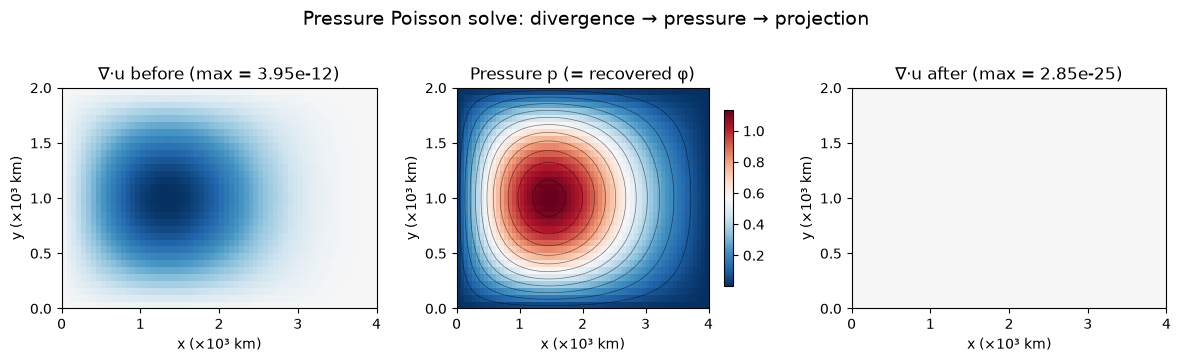

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.5))

# Original divergence
vmax_div = float(jnp.abs(div_uv[1:-1, 1:-1]).max())
axes[0].imshow(
    np.asarray(div_uv[1:-1, 1:-1]),
    origin="lower",
    cmap="RdBu_r",
    aspect="auto",
    vmin=-vmax_div,
    vmax=vmax_div,
    extent=[0, Lx / 1e6, 0, Ly / 1e6],
)
axes[0].set_title(f"∇·u before (max = {max_div_before:.2e})")

# Pressure field
im1 = axes[1].imshow(
    np.asarray(p_interior),
    origin="lower",
    cmap="RdBu_r",
    aspect="auto",
    extent=[0, Lx / 1e6, 0, Ly / 1e6],
)
X_plot = np.linspace(0, Lx / 1e6, nx)
Y_plot = np.linspace(0, Ly / 1e6, ny)
axes[1].contour(
    X_plot,
    Y_plot,
    np.asarray(p_interior),
    levels=12,
    colors="k",
    linewidths=0.5,
    alpha=0.5,
)
axes[1].set_title("Pressure p (= recovered φ)")
fig.colorbar(im1, ax=axes[1], shrink=0.8)

# Corrected divergence
axes[2].imshow(
    np.asarray(div_corr[1:-1, 1:-1]),
    origin="lower",
    cmap="RdBu_r",
    aspect="auto",
    vmin=-vmax_div,
    vmax=vmax_div,
    extent=[0, Lx / 1e6, 0, Ly / 1e6],
)
axes[2].set_title(f"∇·u after (max = {max_div_after:.2e})")

for ax in axes:
    ax.set_xlabel("x (×10³ km)")
    ax.set_ylabel("y (×10³ km)")

fig.suptitle(
    "Pressure Poisson solve: divergence → pressure → projection", fontsize=14, y=1.02
)
fig.tight_layout()
plt.show()

The projection removes divergence to **machine precision** and recovers φ exactly, because the DST-II solve inverts the same discrete Laplacian that the C-grid divergence and gradient compose to with $p = 0$ on the wall faces.

## 3. DST-I vs DST-II: Which Solver?

Both solvers take the T interior as their unknowns; they differ in where the zero sits:

* **DST-II** puts $p = 0$ on the cell **faces**, half a cell outside the first / last T point (`ghost = -interior`): the C-grid wall, and what `Dirichlet1D` imposes.
* **DST-I** puts $p = 0$ on the virtual nodes one step outside, i.e. at the ghost-cell **centres** (`ghost = 0`): a wall half a cell too far out.

Each is the exact inverse of its own discrete operator, so the Laplacian residual alone cannot tell them apart; the distance to φ (which vanishes on the faces) can.

In [9]:
# DST-I: p = 0 at the ghost centres
p_dst1 = gridax.solvers.solve_poisson_dst(rhs, dx, dy)
# DST-II: p = 0 on the faces
p_dst2 = gridax.solvers.solve_poisson_dst2(rhs, dx, dy)

diff = jnp.abs(p_dst1 - p_dst2)
print(f"max |p_DST-I - p_DST-II| = {float(diff.max()):.4e}")
print(f"relative diff = {float(diff.max() / jnp.abs(p_dst1).max()):.4e}")

# Each inverts the Laplacian with its own ghost convention
laplacian_p1 = ops.laplacian(jnp.zeros((Ny, Nx)).at[1:-1, 1:-1].set(p_dst1))
p_dst2_full = jnp.zeros((Ny, Nx)).at[1:-1, 1:-1].set(p_dst2)
laplacian_p2 = ops.laplacian(gridax.fill_ghosts(p_dst2_full, grid, wall))

err_dst1 = float(jnp.abs(laplacian_p1[1:-1, 1:-1] - rhs).max())
err_dst2 = float(jnp.abs(laplacian_p2[1:-1, 1:-1] - rhs).max())
print(f"Laplacian residual (DST-I, ghost = 0):          {err_dst1:.4e}")
print(f"Laplacian residual (DST-II, ghost = -interior): {err_dst2:.4e}")
print(f"max |p_DST-I  - φ| = {float(jnp.abs(p_dst1 - phi[1:-1, 1:-1]).max()):.4e}")
print(f"max |p_DST-II - φ| = {float(jnp.abs(p_dst2 - phi[1:-1, 1:-1]).max()):.4e}")

max |p_DST-I - p_DST-II| = 5.3817e-02
relative diff = 4.5726e-02
Laplacian residual (DST-I, ghost = 0):          5.1133e-25
Laplacian residual (DST-II, ghost = -interior): 2.8434e-25
max |p_DST-I  - φ| = 5.3817e-02
max |p_DST-II - φ| = 3.3307e-16


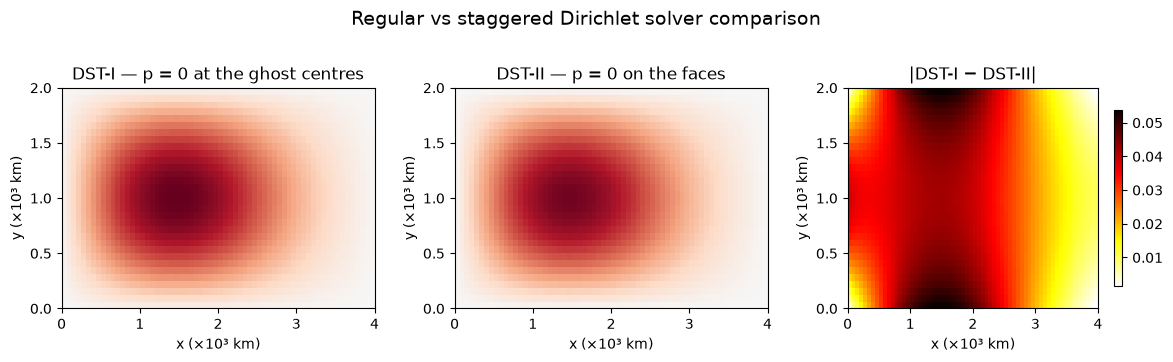

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.5))

vmax = float(jnp.abs(p_dst1).max())

axes[0].imshow(
    np.asarray(p_dst1),
    origin="lower",
    cmap="RdBu_r",
    aspect="auto",
    vmin=-vmax,
    vmax=vmax,
    extent=[0, Lx / 1e6, 0, Ly / 1e6],
)
axes[0].set_title("DST-I — p = 0 at the ghost centres")

axes[1].imshow(
    np.asarray(p_dst2),
    origin="lower",
    cmap="RdBu_r",
    aspect="auto",
    vmin=-vmax,
    vmax=vmax,
    extent=[0, Lx / 1e6, 0, Ly / 1e6],
)
axes[1].set_title("DST-II — p = 0 on the faces")

im = axes[2].imshow(
    np.asarray(diff),
    origin="lower",
    cmap="hot_r",
    aspect="auto",
    extent=[0, Lx / 1e6, 0, Ly / 1e6],
)
axes[2].set_title("|DST-I − DST-II|")
fig.colorbar(im, ax=axes[2], shrink=0.8)

for ax in axes:
    ax.set_xlabel("x (×10³ km)")
    ax.set_ylabel("y (×10³ km)")

fig.suptitle("Regular vs staggered Dirichlet solver comparison", fontsize=14, y=1.02)
fig.tight_layout()
plt.show()

DST-II recovers φ to machine precision: its wall is the C-grid wall. DST-I solves a slightly larger basin (the wall half a cell further out), a first-order error that does not shrink faster than $\Delta x$.

## 4. Module Class Interface

gridax.solvers provides equinox `Module` classes for solver composition. `StaggeredDirichletHelmholtzSolver2D` wraps DST-II and is convenient for cell-centred workflows and JIT compilation.

In [11]:
solver = gridax.solvers.StaggeredDirichletHelmholtzSolver2D(dx=dx, dy=dy, alpha=0.0)
jit_solver = eqx.filter_jit(solver)

p_module = jit_solver(rhs)
print(f"max |module - DST-II| = {float(jnp.abs(p_module - p_dst2).max()):.2e}")

max |module - DST-II| = 4.44e-16


## 5. Convenience Wrapper

sesmax provides one-line convenience functions (in `sesmax_core.gfd`) that dispatch to the correct spectral solver based on the `bc` parameter.

In [12]:
# Pass the full [Ny, Nx] array: the wrapper slices the T interior itself.
p_convenience = gfd.pressure_from_divergence(div_uv, dx, dy, bc="dst")
print(
    "max |convenience - DST-II| = "
    f"{float(jnp.abs(p_convenience[1:-1, 1:-1] - p_dst2).max()):.2e}"
)

max |convenience - DST-II| = 0.00e+00


Here we pass `bc="dst"` (Dirichlet) to match the manufactured test where $\phi = 0$ on the wall faces.  Note that the library default is `bc="dct"` (Neumann, $\partial p / \partial n = 0$), which is the standard choice for pressure with solid walls in most ocean models.

## Summary

| Concept | Detail |
|---------|--------|
| **Pressure location** | T-points (cell centres) on the C-grid |
| **Correct solver** | DST-II: $p = 0$ on the wall faces (`Dirichlet1D`, ghost = −interior) |
| **DST-I** | $p = 0$ at the ghost-cell centres (ghost = 0): the wall half a cell too far out |
| **Projection** | $\mathbf{u}^* = \mathbf{u} - \nabla p$ removes divergence to machine precision |
| **C-grid advantage** | $\partial p/\partial x$ at U-points, $\partial p/\partial y$ at V-points — no interpolation |
| **Module class** | `StaggeredDirichletHelmholtzSolver2D` wraps DST-II for equinox workflows |
| **Convenience** | [`pressure_from_divergence`](xref:api#sesmax_core.pressure_from_divergence)`(div_u, dx, dy)` on the full array — defaults to DCT (Neumann, on the faces) |